In [2]:
import os
os.environ["CUDA_VISIBLE_DEVICES"]='4'
os.environ['HDF5_USE_FILE_LOCKING'] = 'FALSE'
import h5py
import sys
import cv2
import torch
import numpy as np
from tqdm import tqdm
from pathlib import Path
import matplotlib.pyplot as plt
from tqdm import tqdm
import traceback

In [7]:
# h5파일 key 확인
def explore_h5(f, prefix=''):
    for key in f.keys():
        obj = f[key]
        fullname = prefix + '/' + key
        print(f'{fullname}')
        if isinstance(obj, h5py.Dataset):
            print(f'  type  : Dataset')
            print(f'  shape : {obj.shape}')
            print(f'  dtype : {obj.dtype}')
            #print(f'  max : {np.max(obj)} , min : {np.min(obj)}')
        else:
            print(f'  type  : Group')
        if obj.attrs:
            for k, v in obj.attrs.items():
                print(f'  attr  : {k} = {v}')
        if isinstance(obj, h5py.Group):
            explore_h5(obj, fullname)

h5_dir =  '/home/son/orientation-uv-rppg/video_link/CNA_members/KM_preprocess_data/dl_data_CNA_70_withoutoutlier_len300'
files = sorted([f for f in os.listdir(h5_dir) if f.endswith('.h5')])

for subject in files:
    print('='*80)
    print(subject)
    with h5py.File(os.path.join(h5_dir, subject), 'r') as f:
        explore_h5(f)

final_dataset_A001_20250609.h5
/gt_ppg
  type  : Dataset
  shape : (349, 300)
  dtype : float64
/video
  type  : Dataset
  shape : (349, 300, 64, 64)
  dtype : float64
final_dataset_A002_20250609.h5
/gt_ppg
  type  : Dataset
  shape : (303, 300)
  dtype : float64
/video
  type  : Dataset
  shape : (303, 300, 64, 64)
  dtype : float64
final_dataset_A004_20250610.h5
/gt_ppg
  type  : Dataset
  shape : (404, 300)
  dtype : float64
/video
  type  : Dataset
  shape : (404, 300, 64, 64)
  dtype : float32
final_dataset_A005_20250611.h5
/gt_ppg
  type  : Dataset
  shape : (256, 300)
  dtype : float64
/video
  type  : Dataset
  shape : (256, 300, 64, 64)
  dtype : float32
final_dataset_A006_20250611.h5
/gt_ppg
  type  : Dataset
  shape : (375, 300)
  dtype : float64
/video
  type  : Dataset
  shape : (375, 300, 64, 64)
  dtype : float64
final_dataset_A007_20250612.h5
/gt_ppg
  type  : Dataset
  shape : (184, 300)
  dtype : float64
/video
  type  : Dataset
  shape : (184, 300, 64, 64)
  dtype : 

In [26]:
import os
import h5py
import numpy as np

h5_dir = '/home/son/orientation-uv-rppg/video_link/CNA_members/KM_preprocess_data/uv_registration_CNA'
files = sorted([f for f in os.listdir(h5_dir) if f.endswith('.h5')])

results = {}

for fname in files:
    fpath = os.path.join(h5_dir, fname)
    try:
        with h5py.File(fpath, 'r') as f:
            if 'valid_mask' in f:
                # 데이터를 numpy 배열로 로드
                mask = np.array(f['valid_mask'])
                
                # 값이 0인 인덱스 추출 (np.where는 튜플을 반환하므로 [0]으로 인덱스 배열만 가져옴)
                zero_indices = np.where(mask == 0)[0].tolist()
                print(zero_indices[0:30])
                results[fname] = zero_indices
                print(f"[{fname}] 0인 인덱스 개수: {len(zero_indices)}")
            else:
                print(f"[{fname}] 'valid_mask' 키가 없습니다.")
                
    except Exception as e:
        print(f"[{fname}] 파일 읽기 오류: {e}")

# 결과 확인 (예: 첫 번째 파일의 결과만 출력)
# print(results)

[2411, 2412, 2413, 2414, 2415, 2416, 2417, 2418, 2420, 2421, 2422, 2423, 2426, 2427, 2428, 2430, 2431, 2433, 2434, 2435, 2436, 2437, 2438, 2439, 2440, 2441, 2444, 2446, 2447, 2452]
[registration_video_[A001_20250609].h5] 0인 인덱스 개수: 2773
[520, 521, 522, 523, 524, 525, 526, 527, 528, 529, 530, 531, 532, 533, 534, 535, 536, 537, 538, 539, 540, 541, 542, 543, 544, 545, 546, 547, 548, 549]
[registration_video_[A002_20250609].h5] 0인 인덱스 개수: 13126
[121397, 121399, 121403, 121411, 121412, 121413, 121414, 121423, 121426, 121493, 121494, 121495, 121496, 121497, 121498, 121499, 121500, 121501, 121502, 121503, 121504, 121505, 121506, 121507, 121508, 121509, 121510, 121511, 121512, 121513]
[registration_video_[A004_20250610].h5] 0인 인덱스 개수: 674
[793, 794, 795, 796, 797, 798, 799, 800, 801, 802, 803, 804, 805, 806, 807, 808, 809, 810, 811, 812, 813, 814, 815, 816, 817, 818, 819, 820, 821, 822]
[registration_video_[A005_20250611].h5] 0인 인덱스 개수: 50966
[69636, 69637, 69638, 69639, 69640, 69642, 69643, 6

Subject1_motion_940_uv_windowed  mean=-0.000  std=0.163  min=-3.000  max=3.000
Subject1_still_940_uv_windowed  mean=-0.000  std=0.151  min=-3.000  max=3.000
Subject2_motion_940_uv_windowed  mean=-0.000  std=0.164  min=-3.000  max=3.000
Subject2_still_940_uv_windowed  mean=-0.000  std=0.411  min=-3.000  max=3.000
Subject3_motion_940_uv_windowed  mean=-0.000  std=0.190  min=-3.000  max=3.000
Subject3_still_940_uv_windowed  mean=-0.000  std=0.178  min=-3.000  max=3.000
Subject4_motion_940_uv_windowed  mean=-0.000  std=0.166  min=-3.000  max=3.000
Subject4_still_940_uv_windowed  mean=-0.000  std=0.149  min=-3.000  max=3.000
Subject5_still_940_uv_windowed  mean=0.000  std=0.149  min=-3.000  max=3.000
Subject6_motion_940_uv_windowed  mean=-0.000  std=0.164  min=-3.000  max=3.000
Subject6_still_940_uv_windowed  mean=-0.000  std=0.157  min=-3.000  max=3.000
Subject7_motion_940_uv_windowed  mean=-0.000  std=0.176  min=-3.000  max=3.000
Subject7_still_940_uv_windowed  mean=-0.000  std=0.152  min

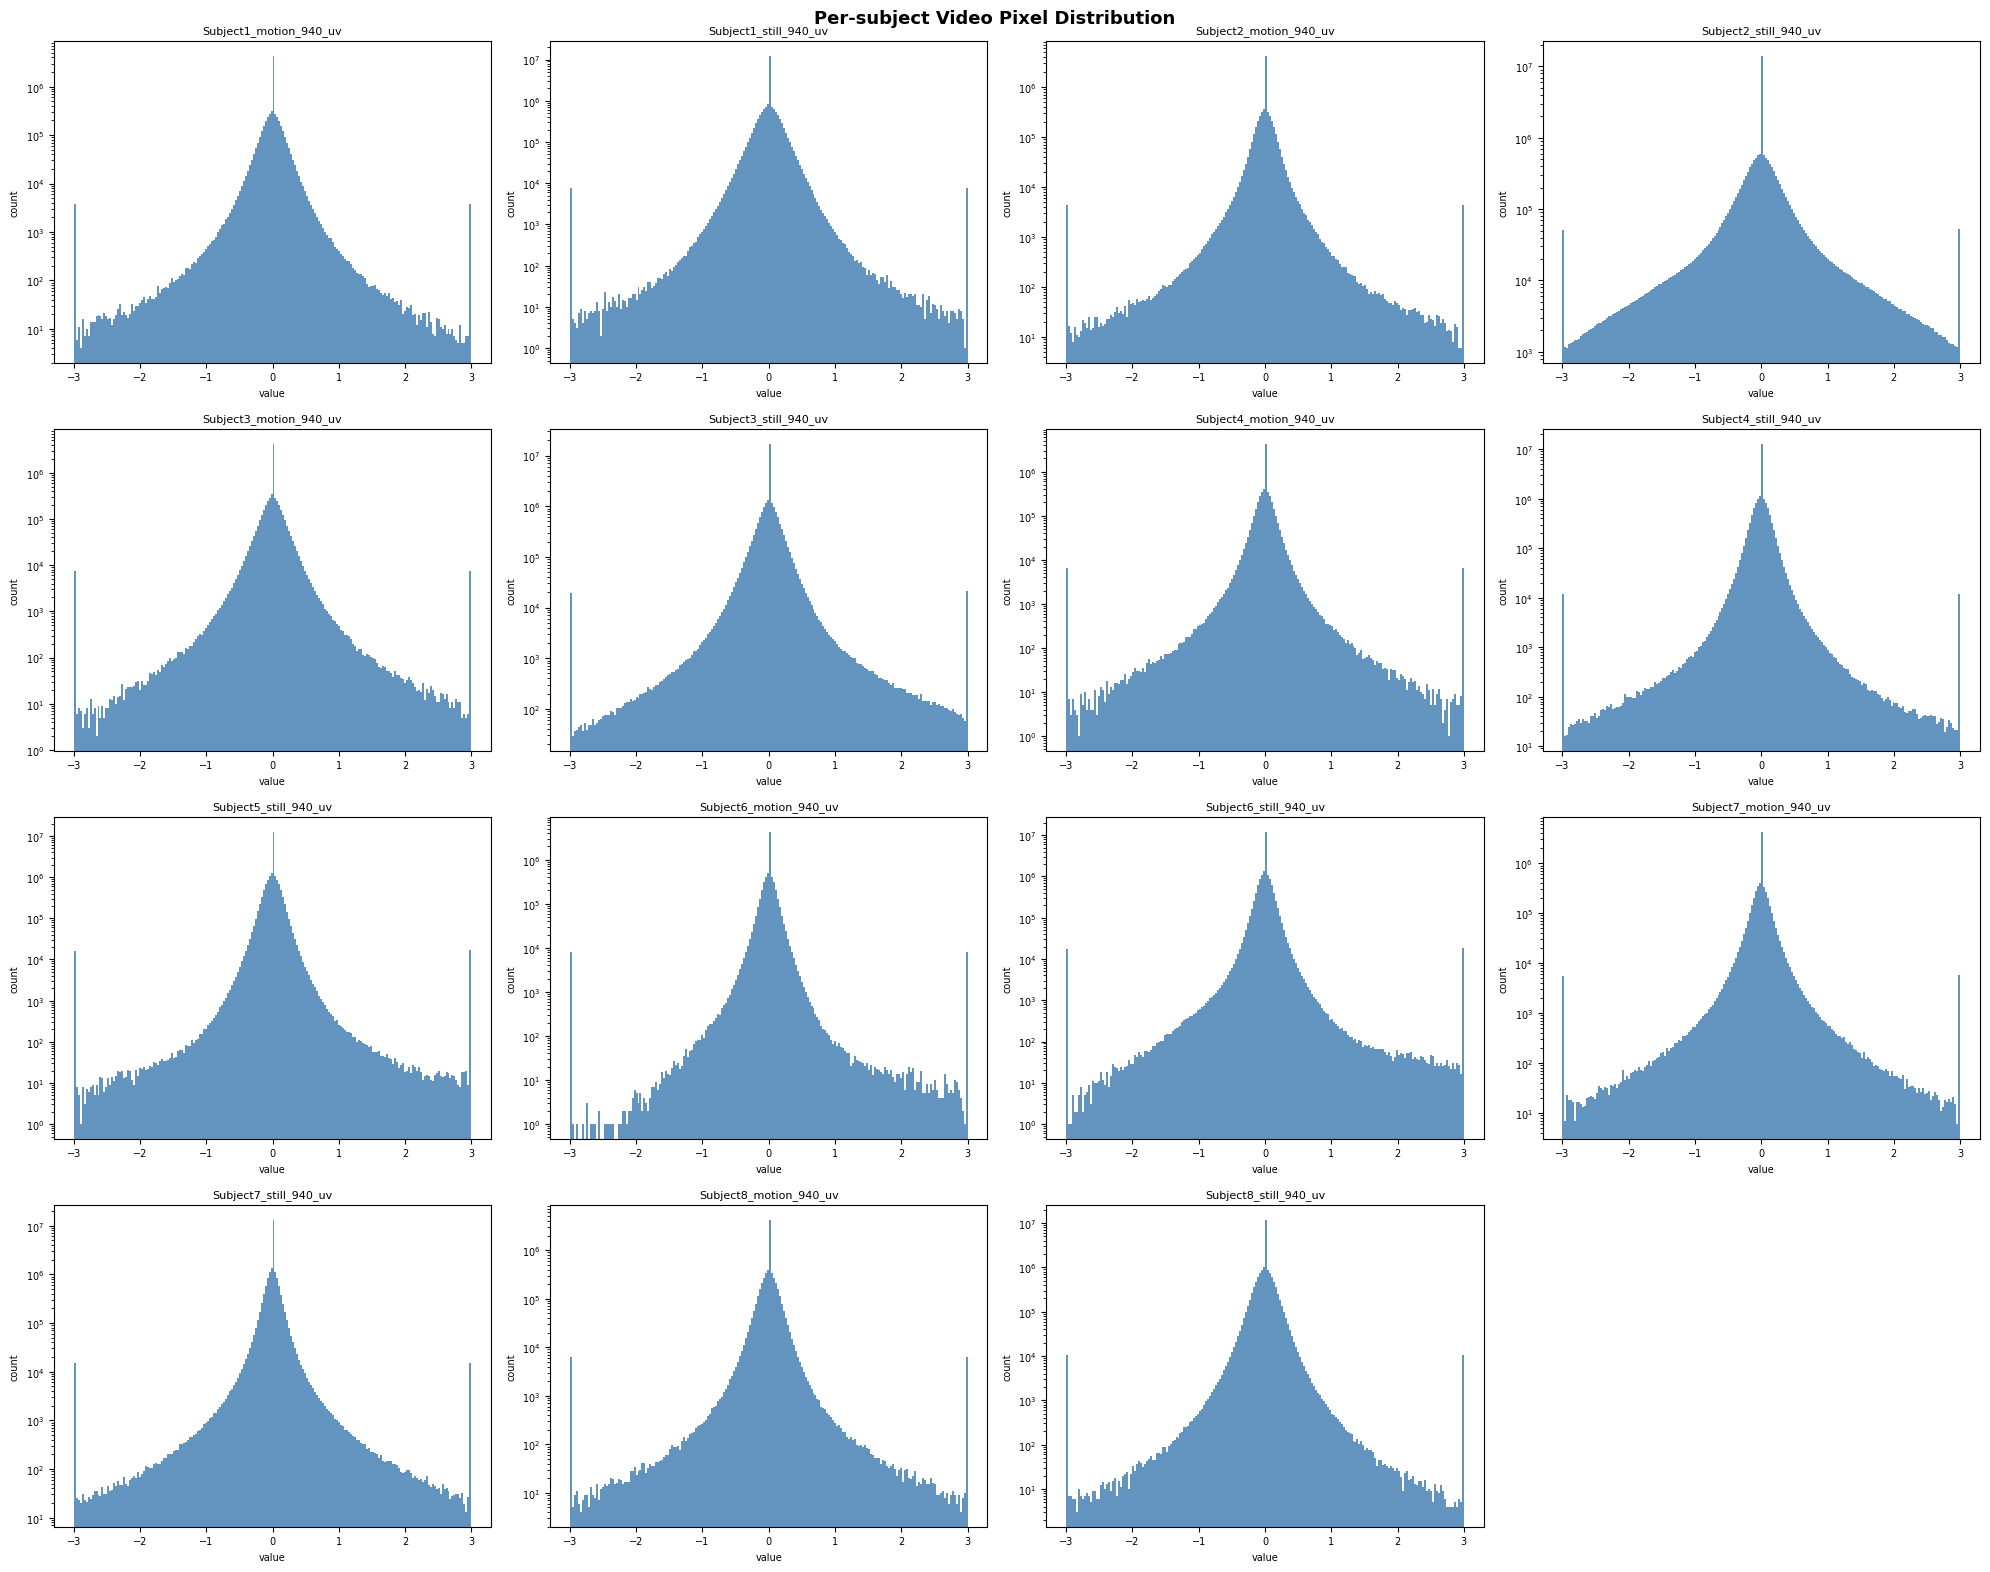

In [46]:
import os
import h5py
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

H5_DIR   = '/nasdata4/2yhy/rPPG_code/rPPG_datasets/raw_data/CNA_members/KM_preprocess_data/mrNIRP_dl_datax'
SAVE_DIR = os.path.join(H5_DIR, 'histogram_plots')
os.makedirs(SAVE_DIR, exist_ok=True)

h5_files = sorted(Path(H5_DIR).glob('*.h5'))
n = len(h5_files)
ncols = 4
nrows = (n + ncols - 1) // ncols

fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 4 * nrows))
axes = axes.ravel()

for i, h5_path in enumerate(h5_files):
    with h5py.File(str(h5_path), 'r') as f:
        flat = f['video'][:].ravel().astype(np.float32)

    axes[i].hist(flat, bins=200, color='steelblue', alpha=0.85, log = True)
    #axes[i].axvline( 3.0, color='red',    lw=1.2, ls='--')
    #axes[i].axvline(-3.0, color='orange', lw=1.2, ls='--')
    axes[i].set_title(h5_path.stem.replace('_windowed', ''), fontsize=8)
    axes[i].set_xlabel('value', fontsize=7)
    axes[i].set_ylabel('count', fontsize=7)
    axes[i].tick_params(labelsize=7)
    print(f"{h5_path.stem}  mean={flat.mean():.3f}  std={flat.std():.3f}  min={flat.min():.3f}  max={flat.max():.3f}")

# 남은 axes 숨기기
for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.suptitle('Per-subject Video Pixel Distribution', fontsize=13, fontweight='bold')
plt.tight_layout()
save_path = os.path.join(SAVE_DIR, 'per_subject_histogram.png')
#plt.savefig(save_path, dpi=150, bbox_inches='tight')
print(f'\n저장: {save_path}')

Subject1_motion_940_uv  mean=0.1474  std=0.1756  min=0.0000  max=0.7077
Subject1_still_940_uv  mean=0.1425  std=0.1704  min=0.0000  max=0.6742
Subject2_motion_940_uv  mean=0.1655  std=0.1876  min=0.0000  max=0.6673
Subject2_still_940_uv  mean=0.1222  std=0.1495  min=0.0000  max=0.8228
Subject3_motion_940_uv  mean=0.1157  std=0.1343  min=0.0000  max=0.5147
Subject3_still_940_uv  mean=0.1439  std=0.1723  min=0.0000  max=0.6986
Subject4_motion_940_uv  mean=0.1904  std=0.2138  min=0.0000  max=0.7751
Subject4_still_940_uv  mean=0.1973  std=0.2227  min=0.0000  max=0.7773
Subject5_still_940_uv  mean=0.1730  std=0.1859  min=0.0000  max=0.6293
Subject6_motion_940_uv  mean=0.1820  std=0.1946  min=0.0000  max=0.5983
Subject6_still_940_uv  mean=0.1838  std=0.1971  min=0.0000  max=0.6129
Subject7_motion_940_uv  mean=0.2152  std=0.2424  min=0.0000  max=0.8118
Subject7_still_940_uv  mean=0.2236  std=0.2549  min=0.0000  max=0.8457
Subject8_motion_940_uv  mean=0.1635  std=0.1821  min=0.0000  max=0.9139

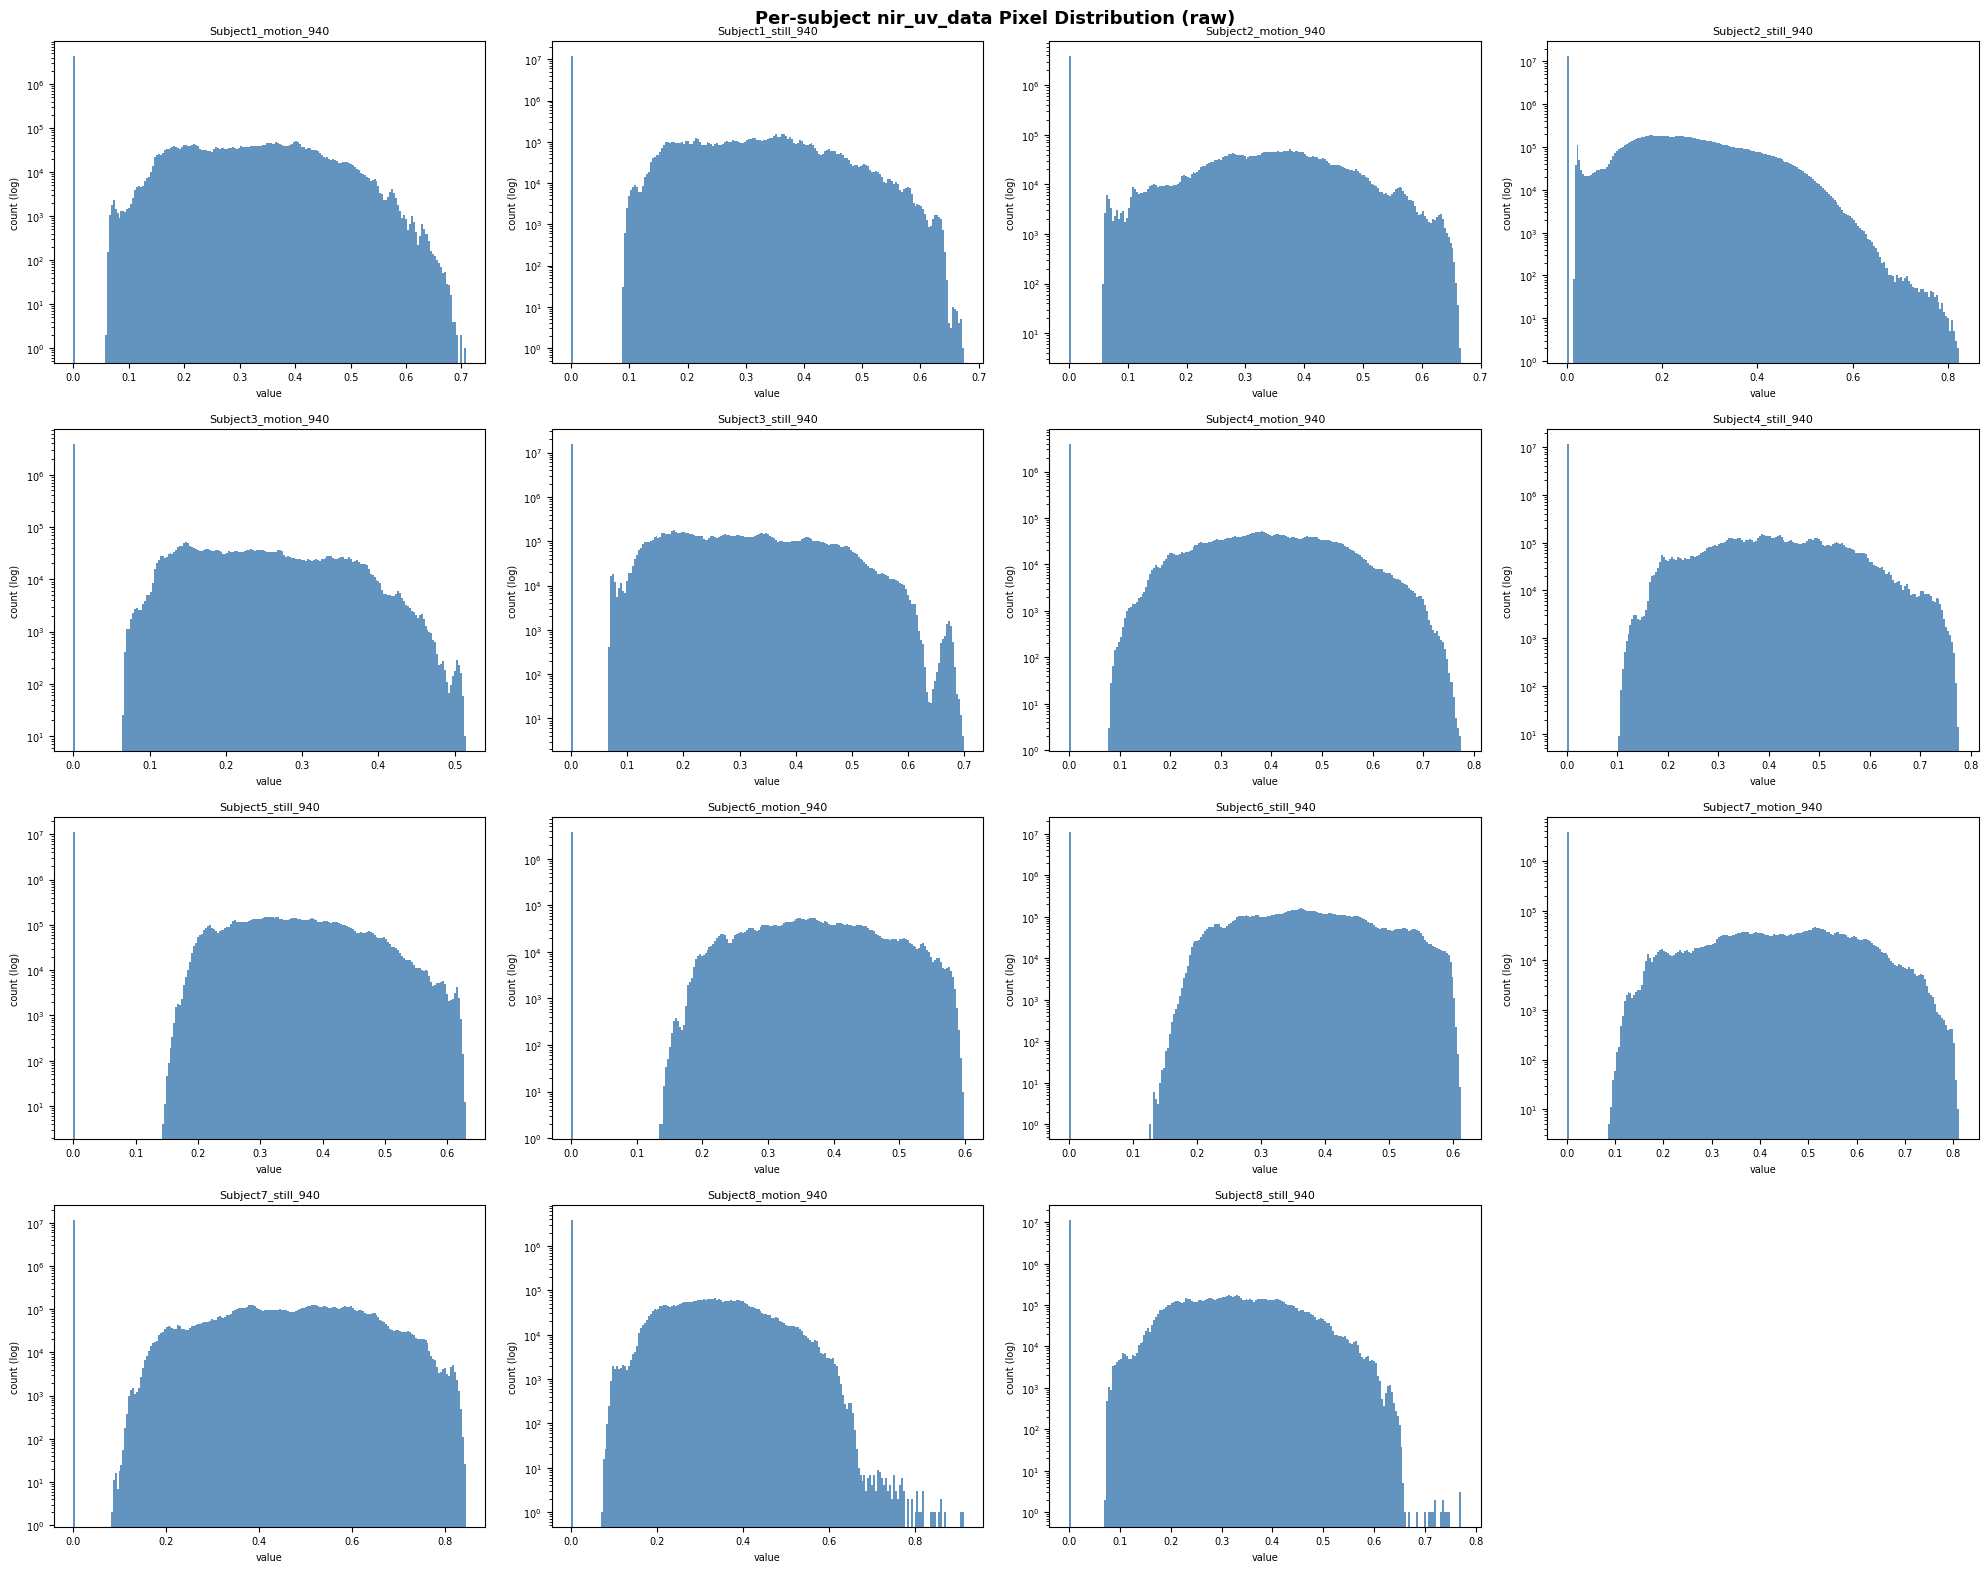

In [48]:
import os
import h5py
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

H5_DIR   = '/nasdata4/2yhy/rPPG_code/rPPG_datasets/raw_data/CNA_members/KM_preprocess_data/MR-nirp_indoor_registration_70'
SAVE_DIR = '/nasdata4/2yhy/rPPG_code/rPPG_datasets/raw_data/CNA_members/KM_preprocess_data/histogram_plots_raw'
os.makedirs(SAVE_DIR, exist_ok=True)

h5_files = sorted(Path(H5_DIR).glob('*.h5'))
n = len(h5_files)
ncols = 4
nrows = (n + ncols - 1) // ncols

fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 4 * nrows))
axes = axes.ravel()

for i, h5_path in enumerate(h5_files):
    with h5py.File(str(h5_path), 'r') as f:
        flat = f['nir_uv_data'][:].ravel().astype(np.float32)

    axes[i].hist(flat, bins=200, color='steelblue', alpha=0.85, log=True)
    axes[i].set_title(h5_path.stem.replace('_uv', ''), fontsize=8)
    axes[i].set_xlabel('value', fontsize=7)
    axes[i].set_ylabel('count (log)', fontsize=7)
    axes[i].tick_params(labelsize=7)
    print(f"{h5_path.stem}  mean={flat.mean():.4f}  std={flat.std():.4f}  min={flat.min():.4f}  max={flat.max():.4f}")

for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.suptitle('Per-subject nir_uv_data Pixel Distribution (raw)', fontsize=13, fontweight='bold')
plt.tight_layout()
save_path = os.path.join(SAVE_DIR, 'per_subject_histogram_raw.png')
plt.savefig(save_path, dpi=150, bbox_inches='tight')
print(f'\n저장: {save_path}')

In [8]:
import h5py
import numpy as np
import matplotlib.pyplot as plt
import os
import glob

PATH_A = "/home/son/orientation-uv-rppg/video_link/CNA_members/KM_preprocess_data/dl_data_CNA_70_withoutoutlier_len300_gtsubjectznorm"
PATH_B = "/home/son/orientation-uv-rppg/video_link/CNA_members/KM_preprocess_data/dl_data_CNA_70_withoutoutlier_len300"

files_a = sorted(glob.glob(os.path.join(PATH_A, "*.h5")))
files_b = sorted(glob.glob(os.path.join(PATH_B, "*.h5")))

print(f"[A] {len(files_a)} files | [B] {len(files_b)} files")

# 공통 파일명 기준으로 매칭
names_a = {os.path.basename(f): f for f in files_a}
names_b = {os.path.basename(f): f for f in files_b}
common = sorted(set(names_a.keys()) & set(names_b.keys()))
print(f"공통 파일 수: {len(common)}")

if not common:
    print("공통 파일이 없습니다. 파일명을 확인하세요.")
    print("A 샘플:", list(names_a.keys())[:5])
    print("B 샘플:", list(names_b.keys())[:5])
    exit()

# 플롯할 파일 수 (최대 6개)
n_plot = min(6, len(common))
fig, axes = plt.subplots(n_plot, 1, figsize=(16, 3 * n_plot))
if n_plot == 1:
    axes = [axes]

for i, fname in enumerate(common[:n_plot]):
    with h5py.File(names_a[fname], 'r') as fa:
        ppg_a = fa['gt_ppg'][:][0]
    with h5py.File(names_b[fname], 'r') as fb:
        ppg_b = fb['gt_ppg'][:][0]

    ax = axes[i]
    t_a = np.arange(len(ppg_a))
    t_b = np.arange(len(ppg_b))

    ax.plot(t_b, ppg_b, color='steelblue', alpha=0.8, linewidth=0.8, label='B: original')
    ax.plot(t_a, ppg_a, color='tomato', alpha=0.8, linewidth=0.8, label='A: gtsubjectznorm')
    ax.set_title(fname, fontsize=9)
    ax.set_xlabel("frame")
    ax.set_ylabel("amplitude")
    ax.legend(fontsize=8, loc='upper right')
    ax.grid(True, alpha=0.3)

    print(f"[{fname}] A shape={ppg_a.shape}, mean={ppg_a.mean():.4f}, std={ppg_a.std():.4f} | "
          f"B shape={ppg_b.shape}, mean={ppg_b.mean():.4f}, std={ppg_b.std():.4f}")

plt.suptitle("gt_ppg comparison: gtsubjectznorm (A, red) vs original (B, blue)", fontsize=11)
plt.tight_layout()
save_path = "/home/son/compare_gt_ppg.png"
plt.savefig(save_path, dpi=150, bbox_inches='tight')
print(f"\n저장 완료: {save_path}")
plt.close()

[A] 16 files | [B] 16 files
공통 파일 수: 16
[final_dataset_A001_20250609.h5] A shape=(300,), mean=0.0100, std=1.6149 | B shape=(300,), mean=0.0000, std=0.9999
[final_dataset_A002_20250609.h5] A shape=(300,), mean=-0.1302, std=1.7164 | B shape=(300,), mean=0.0000, std=1.0000
[final_dataset_A004_20250610.h5] A shape=(300,), mean=-0.0102, std=0.6899 | B shape=(300,), mean=0.0000, std=0.9999
[final_dataset_A005_20250611.h5] A shape=(300,), mean=-0.0136, std=1.1328 | B shape=(300,), mean=-0.0000, std=1.0000
[final_dataset_A006_20250611.h5] A shape=(300,), mean=-0.0417, std=0.8955 | B shape=(300,), mean=-0.0000, std=0.9999
[final_dataset_A007_20250612.h5] A shape=(300,), mean=-0.0094, std=0.6932 | B shape=(300,), mean=-0.0000, std=0.9999

저장 완료: /home/son/compare_gt_ppg.png


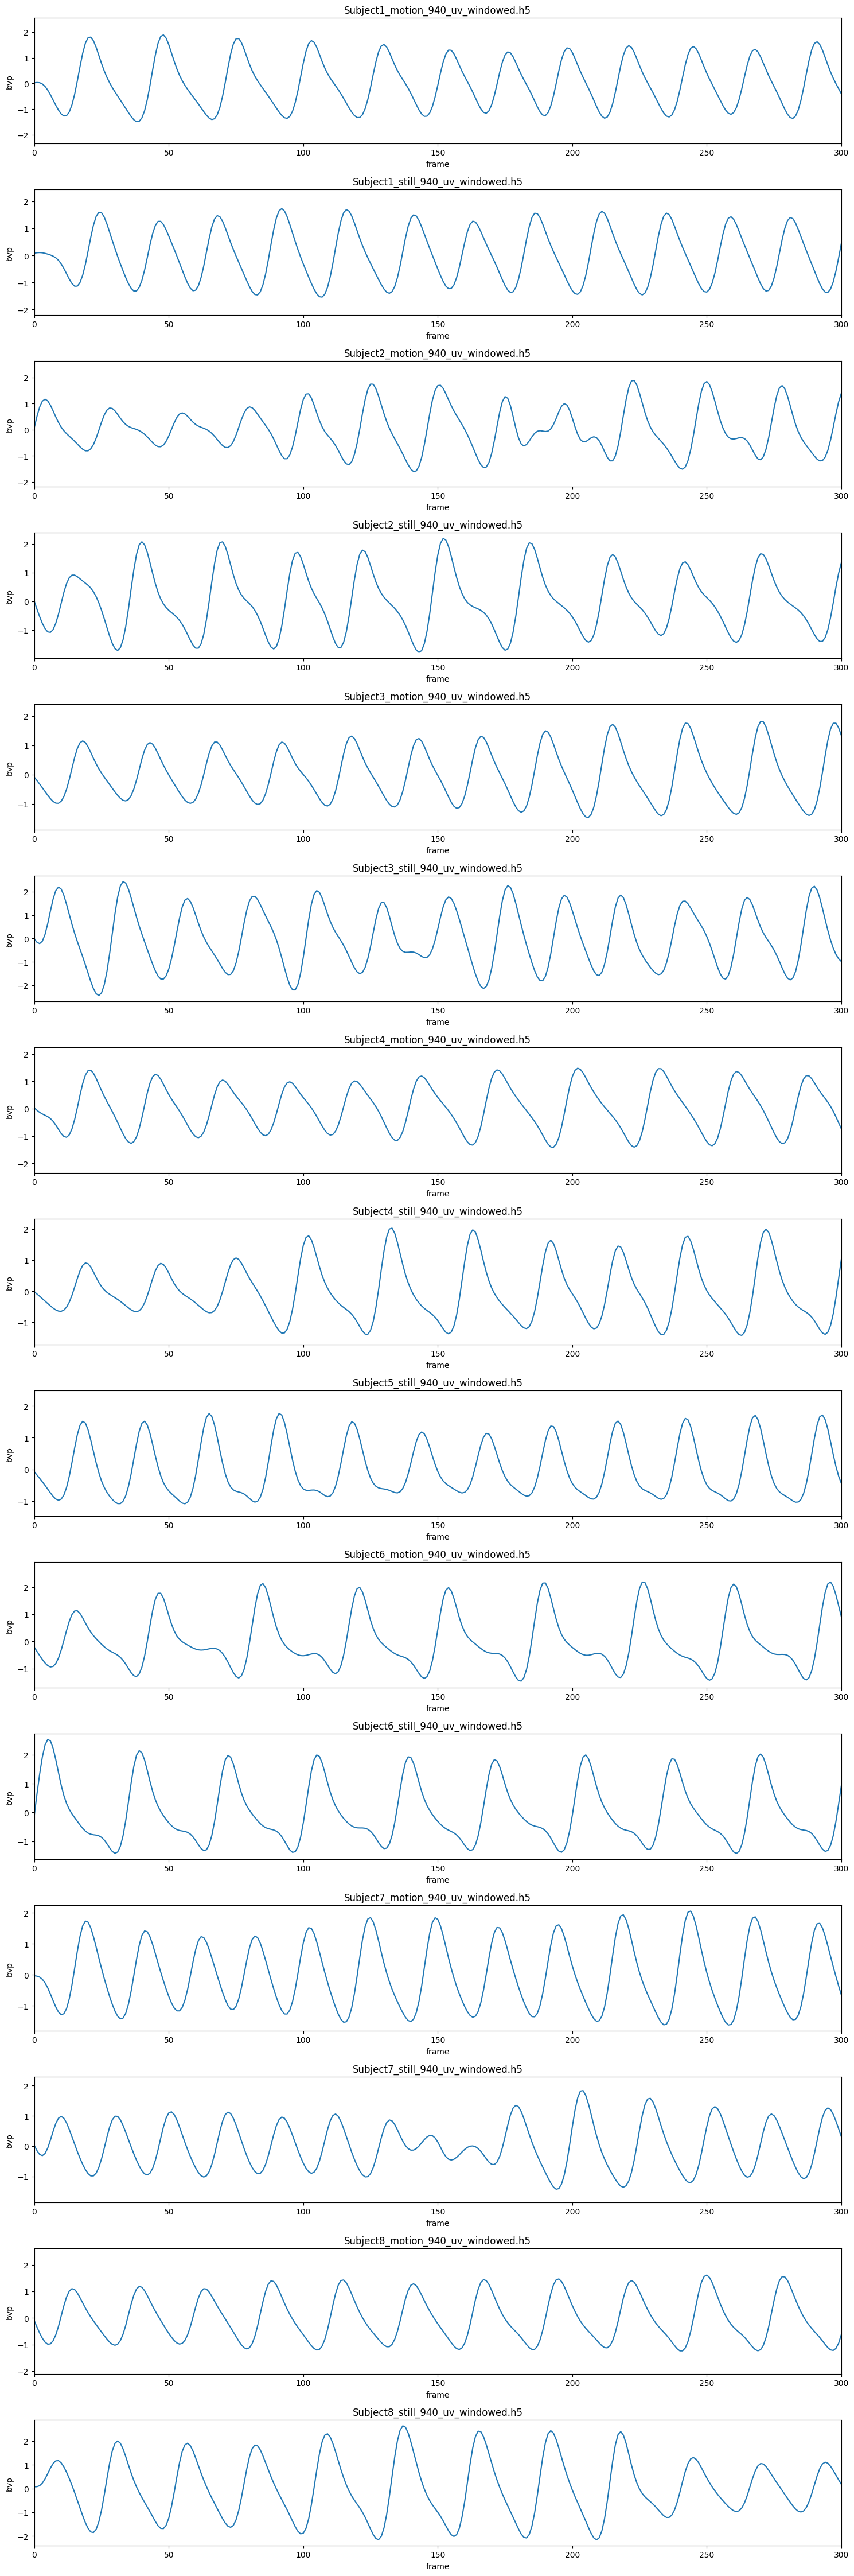

저장완료: bvp_all_subjects.png


In [82]:
# gt ppg 파형확인
import h5py
import os
import matplotlib.pyplot as plt

h5_dir = '/nasdata4/2yhy/rPPG_code/rPPG_datasets/raw_data/CNA_members/KM_preprocess_data/MR-nirp_indoor_dl_data_900frame'
files = sorted([f for f in os.listdir(h5_dir) if f.endswith('.h5')])

fig, axes = plt.subplots(len(files), 1, figsize=(15, 3*len(files)))

for i, subject in enumerate(files):
    with h5py.File(os.path.join(h5_dir, subject), 'r') as f:
        bvp = f['gt_ppg'][:][0]
    
    axes[i].plot(bvp)
    axes[i].set_title(subject)
    axes[i].set_xlim(0, 300)
    axes[i].set_xlabel('frame')
    axes[i].set_ylabel('bvp')

plt.tight_layout()
plt.show()
print("저장완료: bvp_all_subjects.png")

final_dataset_C002_20250703.h5
(900, 64, 64)
float64


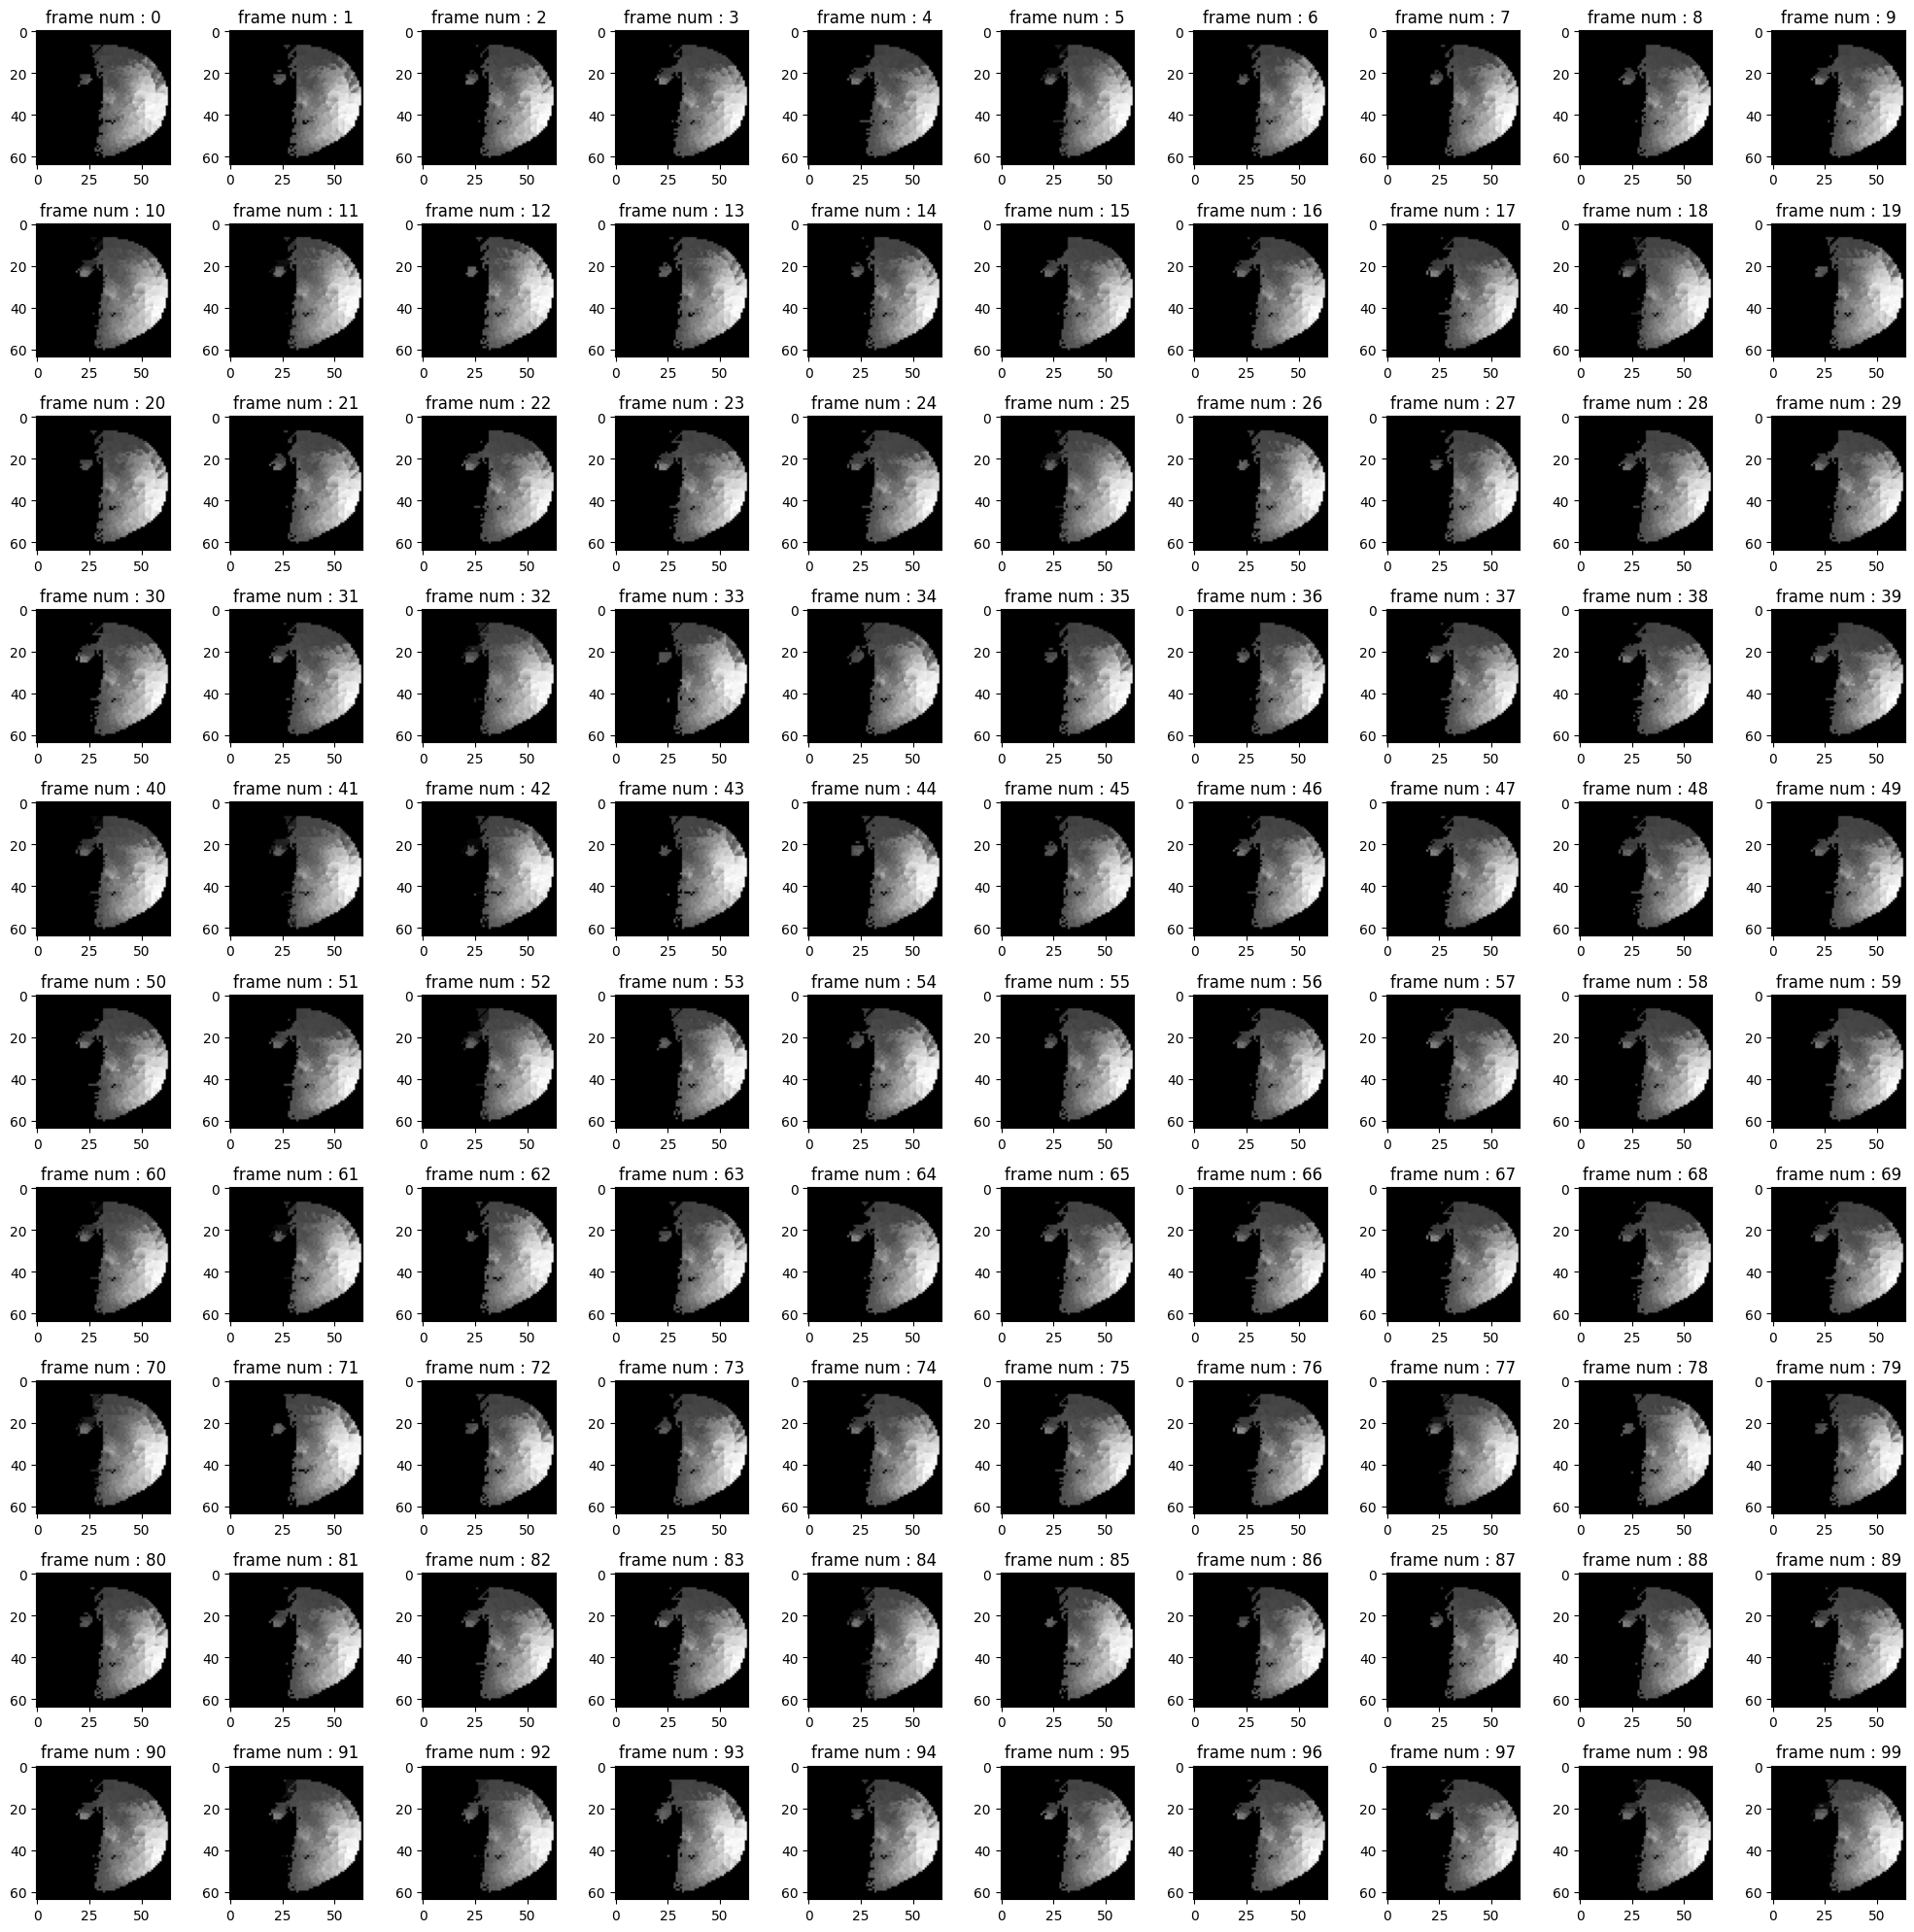

In [31]:
#원본영상확인
id = 14

h5_dir = '/home/son/orientation-uv-rppg/video_link/CNA_members/KM_preprocess_data/dl_data_CNA_70_withoutoutlier'
files = sorted([f for f in os.listdir(h5_dir) if f.endswith('.h5')])
print(files[id])

with h5py.File(os.path.join(h5_dir, files[id]), 'r') as f:
    video = f['video'][3]

print(video.shape)
print(video.dtype)
#비디오 사진 확인
fig, axes = plt.subplots(10, 10, figsize = (20,20))
axes = axes.flatten()
for i, im in enumerate(video[600:700]) :
    #im = im.squeeze(-1)
    axes[i].imshow(im, cmap ='gray')
    axes[i].set_title(f'frame num : {i}')

plt.tight_layout()
plt.show()

In [5]:
#registration 결과 확인
regist_dir ='/nasdata4/2yhy/rPPG_code/rPPG_datasets/raw_data/CNA_members/KM_preprocess_data/IMVIA-NIR_registration'
people = sorted(os.listdir(regist_dir))

id = 3
print(people[id])
with h5py.File(os.path.join(regist_dir, people[id]), 'r') as f:
    video = f['nir_uv_data'][:]

print(video.shape)
print(video.dtype)


fig, axes = plt.subplots(5,5, figsize = (20,20))
axes = axes.flatten()
for i, im in enumerate(video[:25]) :

    axes[i].imshow(im, cmap ='gray')
    axes[i].set_title(f'frame num : {i}')

plt.tight_layout()
plt.show()

FileNotFoundError: [Errno 2] No such file or directory: '/nasdata4/2yhy/rPPG_code/rPPG_datasets/raw_data/CNA_members/KM_preprocess_data/IMVIA-NIR_registration'

13_uv_windowed.h5
(4, 300, 64, 64)
float32
0.9194128
0.0


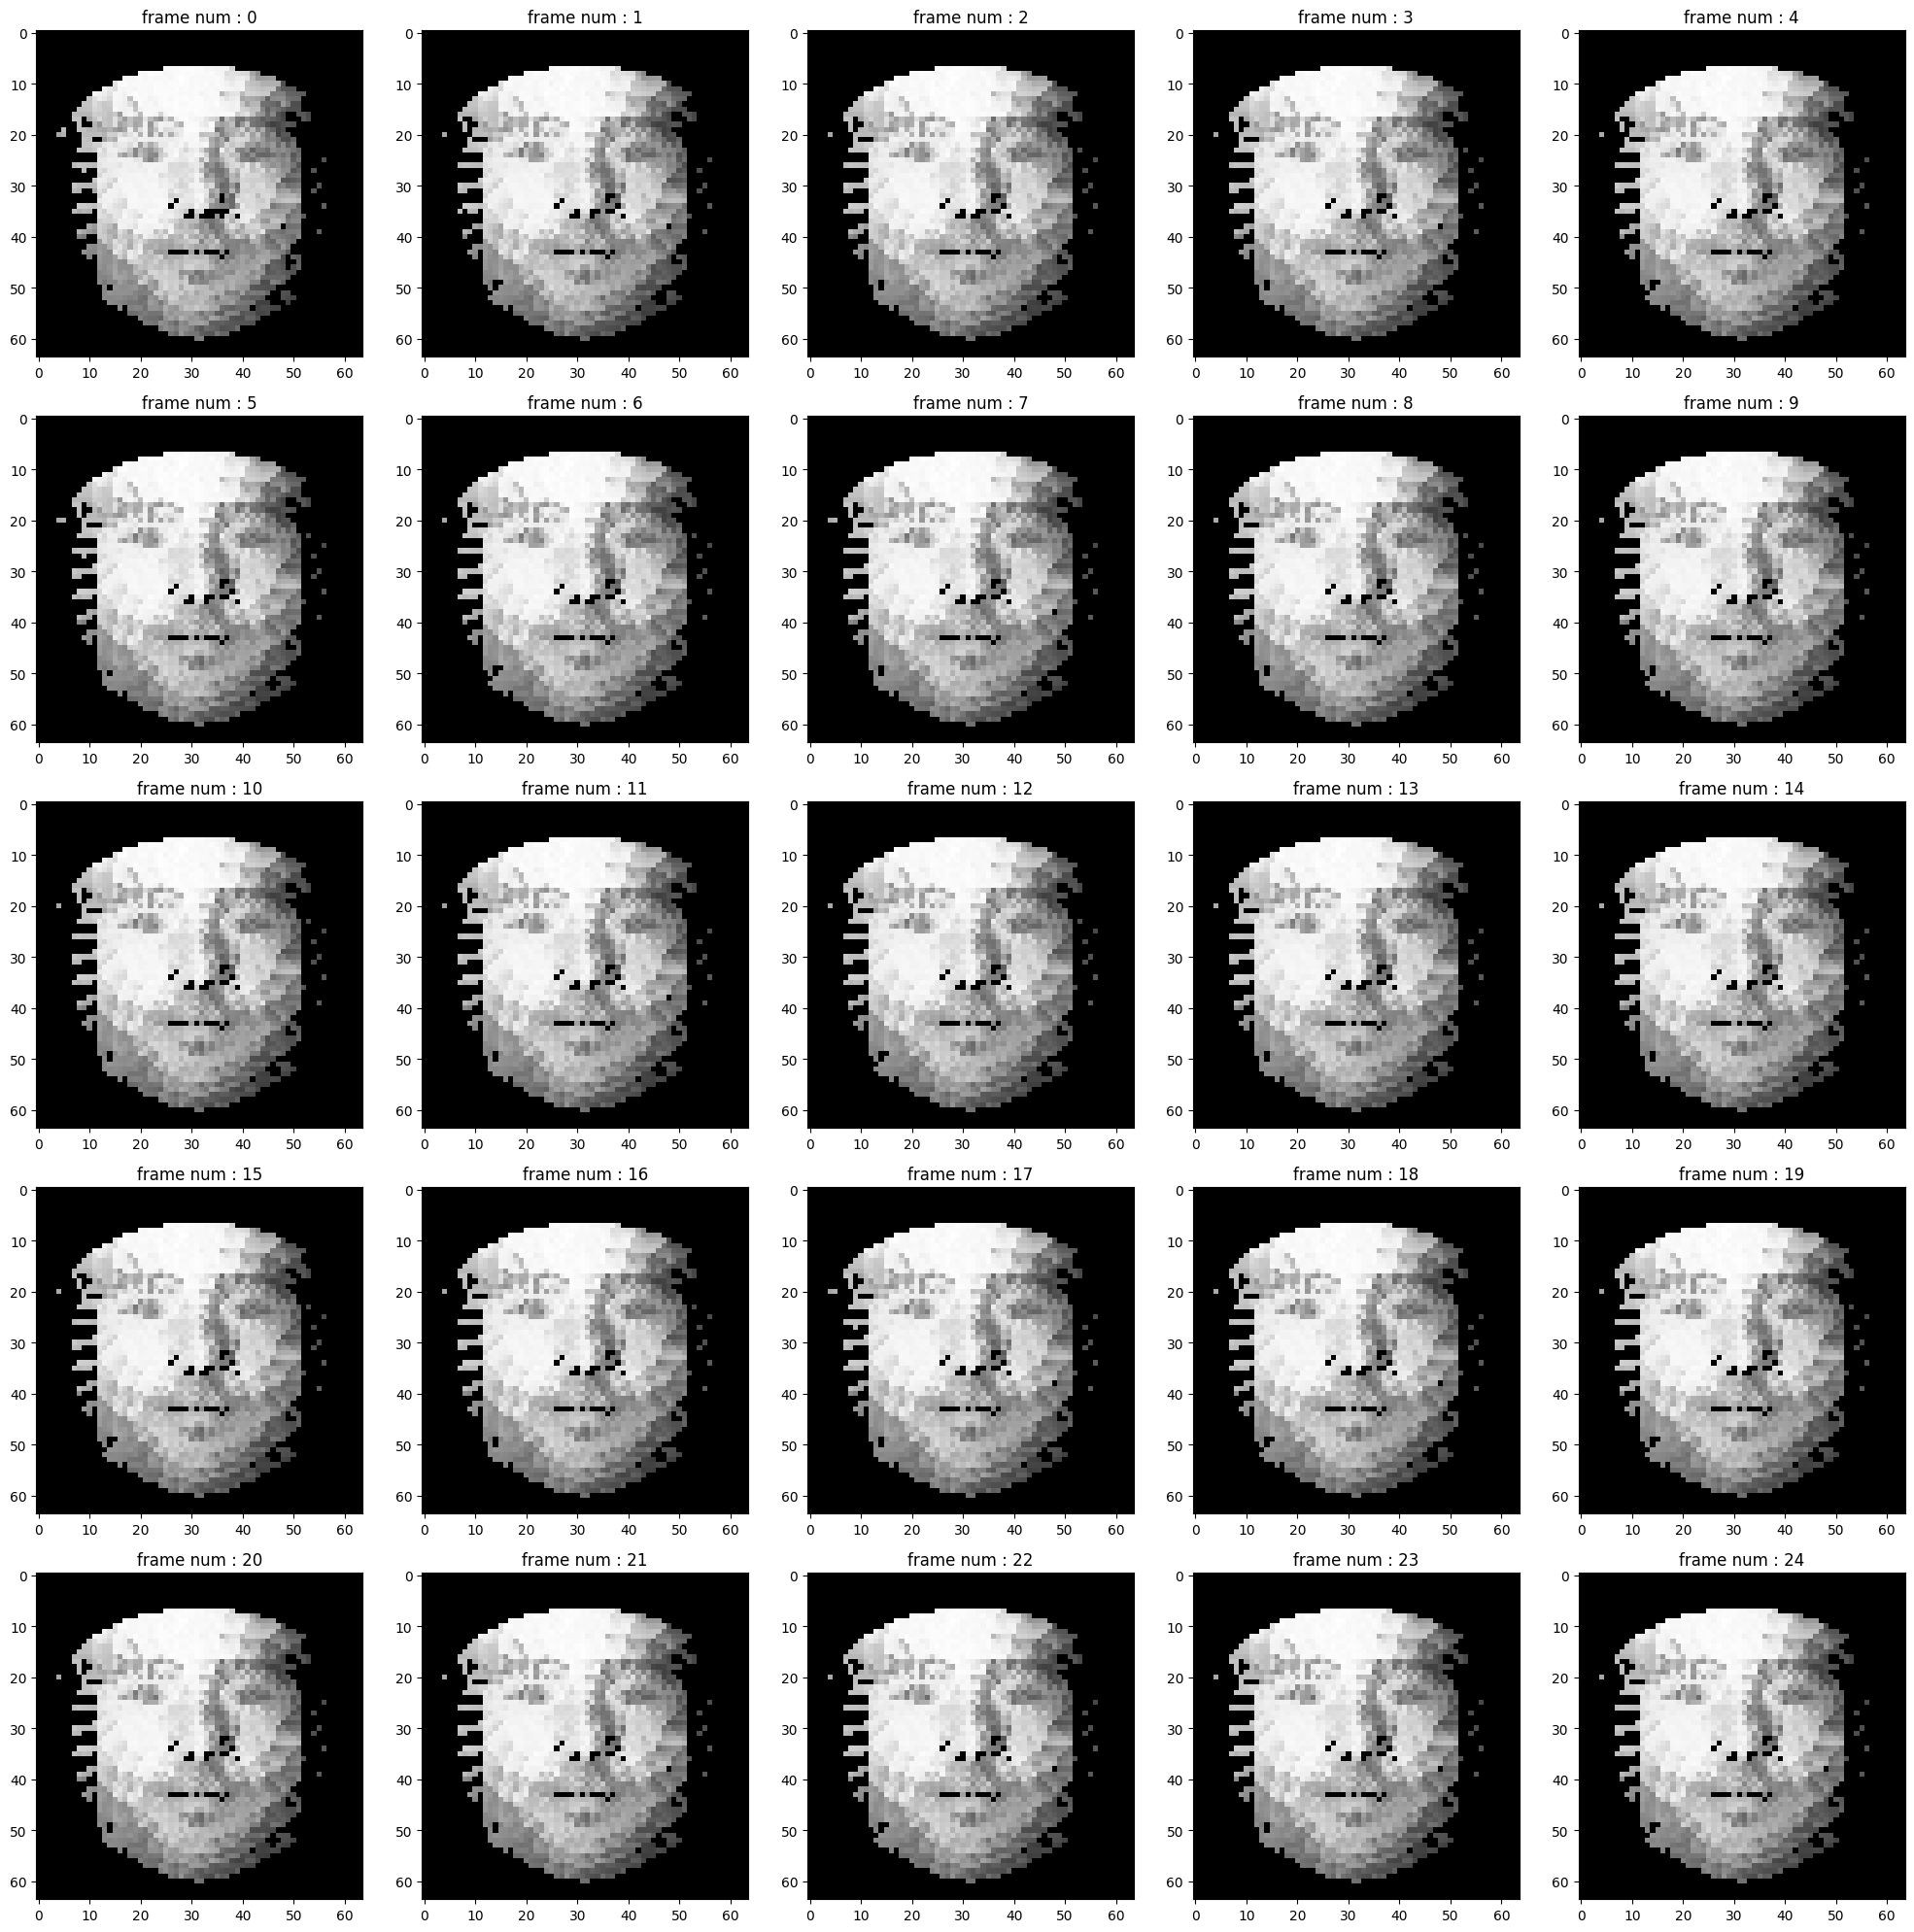

In [12]:
#dl_data 확인
regist_dir ='/nasdata4/2yhy/rPPG_code/rPPG_datasets/raw_data/CNA_members/KM_preprocess_data/IMVIA-NIR_dl_data'
people = sorted(os.listdir(regist_dir))

id = 3
print(people[id])
with h5py.File(os.path.join(regist_dir, people[id]), 'r') as f:
    video = f['video'][:]

print(video.shape)
print(video.dtype)
print(np.max(video))
print(np.min(video))


fig, axes = plt.subplots(5,5, figsize = (20,20))
axes = axes.flatten()
for i, im in enumerate(video[0][:25]) :

    axes[i].imshow(im, cmap ='gray')
    axes[i].set_title(f'frame num : {i}')

plt.tight_layout()
plt.show()

In [19]:
#dl_data 확인
regist_dir ='/nasdata4/2yhy/rPPG_code/rPPG_datasets/raw_data/CNA_members/KM_preprocess_data/raw_video'
people = sorted(os.listdir(regist_dir))

id = 3
print(people[id])
with h5py.File(os.path.join(regist_dir, people[id]), 'r') as f:
    video = f['video'][:]

print(video.shape)
print(video.dtype)
print(np.max(video))
print(np.min(video))


fig, axes = plt.subplots(5,5, figsize = (20,20))
axes = axes.flatten()
for i, im in enumerate(video[:25]) :

    axes[i].imshow(im, cmap ='gray')
    axes[i].set_title(f'frame num : {i}')

plt.tight_layout()
plt.show()

raw_video_[A004_20250610].h5
(123421, 220, 350)
uint8


KeyboardInterrupt: 

In [ ]:
all_sub_list = [i for i in subject_file_map.keys()]

folded_list = np.array_split(all_sub_list, k)
folded_list = [list(k) for k in folded_list]

for i, valid_list in enumerate(folded_list) :
    train_list = [k for k in all_sub_list if k not in valid_list]

    train_ds = [*s for j in train_list for s in subject_file_map[j]]